In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from PIL import Image

PROJECT_ROOT = Path.cwd()
DATASET_ROOT = PROJECT_ROOT / "datasets"
FEATURES_DIR = PROJECT_ROOT / "features"
FEATURES_DIR.mkdir(exist_ok=True)

SPLITS = ("train", "test")
SPLIT_COLORS = {"train": "tab:blue", "test": "tab:orange"}
TARGET = "pm25"
TARGET_LABEL = "PM2.5 AQI (US EPA scale)"
AQI_BIN_EDGES = [0, 50, 100, 150, 200, 300, 600]
AQI_BIN_ORDER = ["0–50", "51–100", "101–150", "151–200", "201–300", "301–600"]
RANDOM_SEED = 42
LOADER_THREADS = 8
BATCH_SIZE = 64
FILTER_IMAGE_SIZE = (384, 512)
DEEP_IMAGE_SIZE = (240, 320)
SKY_ROI_FRACTION = 1 / 3
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")

rng = np.random.default_rng(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device {DEVICE} | cwd {PROJECT_ROOT.name}")

torch 2.14.1 | torchvision 0.29.1 | device mps | cwd acit-4620-projects


In [2]:
def load_split_metadata(split):
    split_metadata = pd.read_csv(DATASET_ROOT / split / "metadata.csv")
    split_metadata["split"] = split
    split_metadata["image_path"] = [str(DATASET_ROOT / split / "images" / filename) for filename in split_metadata["filename"]]
    return split_metadata


raw_metadata = pd.concat([load_split_metadata(split) for split in SPLITS], ignore_index=True)
raw_metadata["captured_at"] = pd.to_datetime(raw_metadata["captured_at"])
raw_metadata["pm25_bin"] = pd.Categorical(raw_metadata["pm25_bin"], categories=AQI_BIN_ORDER, ordered=True)
print(raw_metadata.groupby("split").size().rename("metadata_rows").to_string())
raw_metadata.head()

split
test     2921
train    8298


,image_id,station_id,captured_at,camera_angle,longitude,latitude,quality_score,downloaded_at,pm25,filename,quality,pm25_bin,split,image_path
0,1299925057505266,13051,2024-01-17,NaN,121.293349,25.027580,NaN,2025-09-12T08:00:56.871094,39.0,1299925057505266.jpg,good,0–50,train,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...
1,924249681642820,3705,2017-12-30,NaN,139.235777,35.354056,NaN,2025-09-07T22:39:44.846055,19.0,924249681642820.jpg,good,0–50,train,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...
2,498043544721455,3278,2020-01-02,NaN,145.714003,-40.989167,NaN,2025-09-07T18:25:10.505759,9.0,498043544721455.jpg,good,0–50,train,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...
3,944035996420125,11580,2019-06-27,NaN,32.024932,-28.747296,NaN,2025-09-11T21:11:04.811658,31.0,944035996420125.jpg,good,0–50,train,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...
4,886419591948919,6894,2020-04-24,NaN,4.833378,43.933108,NaN,2025-09-09T14:24:31.876920,41.0,886419591948919.jpg,good,0–50,train,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...


In [3]:
schema_report = pd.DataFrame({
    "dtype": raw_metadata.dtypes.astype(str),
    "missing_share": raw_metadata.isna().mean().round(3),
    "unique_values": raw_metadata.nunique(dropna=True),
})
schema_report

,dtype,missing_share,unique_values
image_id,int64,0.0,11096
station_id,int64,0.0,3261
captured_at,datetime64[us],0.0,2387
camera_angle,float64,1.0,0
longitude,float64,0.0,10799
latitude,float64,0.0,10779
quality_score,float64,1.0,0
downloaded_at,str,0.0,11219
pm25,float64,0.0,284
filename,str,0.0,11096


In [4]:
uninformative_columns = [
    column for column in raw_metadata.columns
    if column != "split" and raw_metadata[column].nunique(dropna=True) <= 1
]
scrape_bookkeeping_columns = ["downloaded_at"]
print("dropping uninformative columns:", uninformative_columns)
print("dropping scrape bookkeeping columns:", scrape_bookkeeping_columns)
metadata = raw_metadata.drop(columns=uninformative_columns + scrape_bookkeeping_columns)

dropping uninformative columns: ['camera_angle', 'quality_score', 'quality']
dropping scrape bookkeeping columns: ['downloaded_at']


In [5]:
images_on_disk = {split: {path.name for path in (DATASET_ROOT / split / "images").glob("*.jpg")} for split in SPLITS}
metadata["file_exists"] = [filename in images_on_disk[split] for filename, split in zip(metadata["filename"], metadata["split"])]
files_without_metadata = {
    split: len(images_on_disk[split] - set(metadata.loc[metadata["split"] == split, "filename"]))
    for split in SPLITS
}
print("image files on disk:", {split: len(names) for split, names in images_on_disk.items()})
print("metadata rows whose image file is missing:", int((~metadata["file_exists"]).sum()))
print("image files without a metadata row:", files_without_metadata)

image files on disk: {'train': 8194, 'test': 2920}
metadata rows whose image file is missing: 0
image files without a metadata row: {'train': 0, 'test': 0}


In [6]:
rows_per_image = metadata.groupby("image_id").agg(
    rows=("split", "size"),
    splits=("split", lambda splits: "+".join(sorted(set(splits)))),
    linked_stations=("station_id", "nunique"),
    capture_days=("captured_at", "nunique"),
    pm25_values=(TARGET, lambda values: sorted(set(values))),
)
shared_images = rows_per_image[rows_per_image["rows"] > 1].copy()
shared_images["pm25_spread"] = shared_images["pm25_values"].map(lambda values: max(values) - min(values))
conflicting_images = shared_images[shared_images["pm25_spread"] > 0]

print("images listed in more than one metadata row:", len(shared_images))
print(shared_images["splits"].value_counts().rename("images").to_string())
print("shared images linked to several stations:", int((shared_images["linked_stations"] > 1).sum()))
print("shared images with conflicting AQI labels:", len(conflicting_images))
print("AQI spread of conflicting labels:", conflicting_images["pm25_spread"].describe().round(1).to_dict())
shared_images.sort_values("pm25_spread", ascending=False).head(10)

images listed in more than one metadata row: 80
splits
train         61
test+train    18
test           1
shared images linked to several stations: 80
shared images with conflicting AQI labels: 71
AQI spread of conflicting labels: {'count': 71.0, 'mean': 12.5, 'std': 14.2, 'min': 2.0, '25%': 8.0, '50%': 9.0, '75%': 9.0, 'max': 93.0}


,rows,splits,linked_stations,capture_days,pm25_values,pm25_spread
image_id,,,,,,
730858772245569,2,train,2,1,"[118.0, 211.0]",93.0
2890879174492271,3,train,3,1,"[70.0, 110.0, 121.0]",51.0
292049135803422,2,test+train,2,1,"[397.0, 445.0]",48.0
485625305923271,2,test+train,2,1,"[70.0, 114.0]",44.0
178403940832524,2,train,2,1,"[70.0, 110.0]",40.0
3172611009722014,2,test+train,2,1,"[16.0, 56.0]",40.0
3747075522064398,2,train,2,1,"[114.0, 141.0]",27.0
761866687810484,2,test+train,2,1,"[109.0, 132.0]",23.0
320082056133742,2,test+train,2,1,"[109.0, 132.0]",23.0


In [7]:
images_in_both_splits = set(shared_images.index[shared_images["splits"] == "test+train"])
metadata_without_leakage = metadata[~((metadata["split"] == "train") & metadata["image_id"].isin(images_in_both_splits))]

clean_metadata = (
    metadata_without_leakage
    .groupby(["split", "image_id"], as_index=False, sort=False)
    .agg(
        station_id=("station_id", "first"),
        linked_stations=("station_id", "nunique"),
        captured_at=("captured_at", "first"),
        longitude=("longitude", "mean"),
        latitude=("latitude", "mean"),
        pm25=(TARGET, "median"),
        filename=("filename", "first"),
        image_path=("image_path", "first"),
    )
)
clean_metadata["pm25_bin"] = pd.cut(clean_metadata[TARGET], bins=AQI_BIN_EDGES, labels=AQI_BIN_ORDER, include_lowest=True)

provided_bins = metadata.drop_duplicates("image_id").set_index("image_id")["pm25_bin"].astype(str)
unshared = clean_metadata[~clean_metadata["image_id"].isin(shared_images.index)]
bin_agreement = (unshared["pm25_bin"].astype(str).to_numpy() == provided_bins.loc[unshared["image_id"]].to_numpy()).mean()

train_ids = set(clean_metadata.loc[clean_metadata["split"] == "train", "image_id"])
test_ids = set(clean_metadata.loc[clean_metadata["split"] == "test", "image_id"])
print(f"metadata rows: {len(metadata)} -> clean images: {len(clean_metadata)}")
print("train images removed because they also appear in test:", len(images_in_both_splits))
print("image overlap between train and test after cleaning:", len(train_ids & test_ids))
print(f"recomputed AQI category matches the provided one for {bin_agreement:.1%} of unshared images")
print(clean_metadata.groupby("split").size().rename("clean_images").to_string())

metadata rows: 11219 -> clean images: 11096
train images removed because they also appear in test: 18
image overlap between train and test after cleaning: 0
recomputed AQI category matches the provided one for 100.0% of unshared images
split
test     2920
train    8176


In [8]:
def approximate_region(latitude, longitude):
    if longitude < -30:
        return "North America" if latitude >= 15 else "Latin America"
    if latitude < -10 and longitude >= 110:
        return "Oceania"
    if longitude < 45 and latitude >= 35:
        return "Europe"
    if 34 <= longitude < 63 and latitude >= 12:
        return "Middle East"
    if longitude < 52 and latitude < 35:
        return "Africa"
    return "Asia"


clean_metadata["region"] = [approximate_region(lat, lon) for lat, lon in zip(clean_metadata["latitude"], clean_metadata["longitude"])]
clean_metadata["hemisphere"] = np.where(clean_metadata["latitude"] >= 0, "north", "south")
clean_metadata["year"] = clean_metadata["captured_at"].dt.year
clean_metadata["month"] = clean_metadata["captured_at"].dt.month
clean_metadata["log_pm25"] = np.log1p(clean_metadata[TARGET])
clean_metadata.head()

,split,image_id,station_id,linked_stations,captured_at,longitude,latitude,pm25,filename,image_path,pm25_bin,region,hemisphere,year,month,log_pm25
0,train,1299925057505266,13051,1,2024-01-17,121.293349,25.027580,39.0,1299925057505266.jpg,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...,0–50,Asia,north,2024,1,3.688879
1,train,924249681642820,3705,1,2017-12-30,139.235777,35.354056,19.0,924249681642820.jpg,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...,0–50,Asia,north,2017,12,2.995732
2,train,498043544721455,3278,1,2020-01-02,145.714003,-40.989167,9.0,498043544721455.jpg,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...,0–50,Oceania,south,2020,1,2.302585
3,train,944035996420125,11580,1,2019-06-27,32.024932,-28.747296,31.0,944035996420125.jpg,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...,0–50,Africa,south,2019,6,3.465736
4,train,886419591948919,6894,1,2020-04-24,4.833378,43.933108,41.0,886419591948919.jpg,/Users/lithasan/Desktop/oslomet/ACIT 4620-C/ac...,0–50,Europe,north,2020,4,3.737670


        count   mean   std  min   25%    50%    75%    max
split                                                     
test   2920.0  119.4  81.5  2.0  54.0  114.0  165.0  416.0
train  8176.0  121.8  88.4  1.0  54.0  111.0  164.0  530.0

split     train_share  test_share
pm25_bin                         
0–50            0.217       0.215
51–100          0.217       0.216
101–150         0.215       0.216
151–200         0.217       0.216
201–300         0.089       0.094
301–600         0.043       0.043


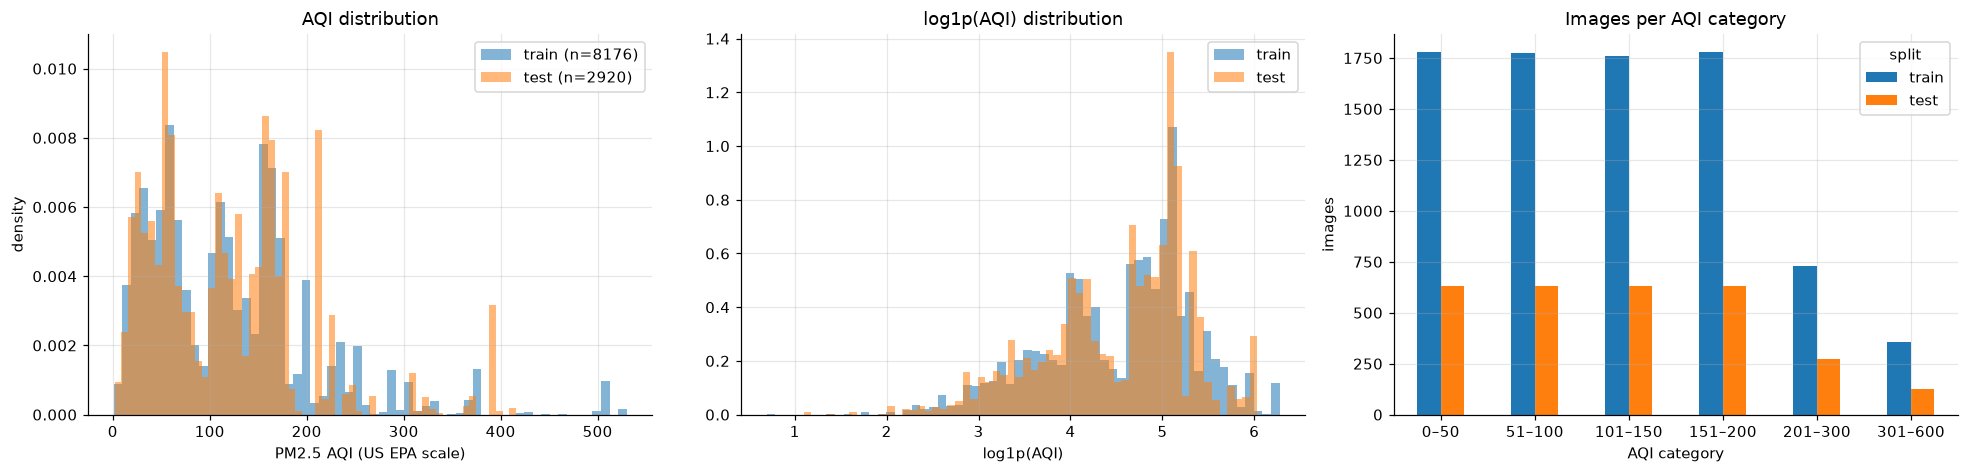

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
for split in SPLITS:
    split_values = clean_metadata.loc[clean_metadata["split"] == split, TARGET]
    axes[0].hist(split_values, bins=60, density=True, alpha=0.55, color=SPLIT_COLORS[split], label=f"{split} (n={len(split_values)})")
    axes[1].hist(np.log1p(split_values), bins=60, density=True, alpha=0.55, color=SPLIT_COLORS[split], label=split)
axes[0].set(title="AQI distribution", xlabel=TARGET_LABEL, ylabel="density")
axes[1].set(title="log1p(AQI) distribution", xlabel="log1p(AQI)")
images_per_bin = clean_metadata.groupby(["pm25_bin", "split"], observed=False).size().unstack("split")[list(SPLITS)]
images_per_bin.plot.bar(ax=axes[2], color=[SPLIT_COLORS[split] for split in SPLITS], rot=0)
axes[2].set(title="Images per AQI category", xlabel="AQI category", ylabel="images")
for ax in axes[:2]:
    ax.legend()
plt.tight_layout()
plt.show()

print(clean_metadata.groupby("split")[TARGET].describe().round(1).to_string())
print()
print((images_per_bin / images_per_bin.sum()).round(3).rename(columns=lambda split: f"{split}_share").to_string())

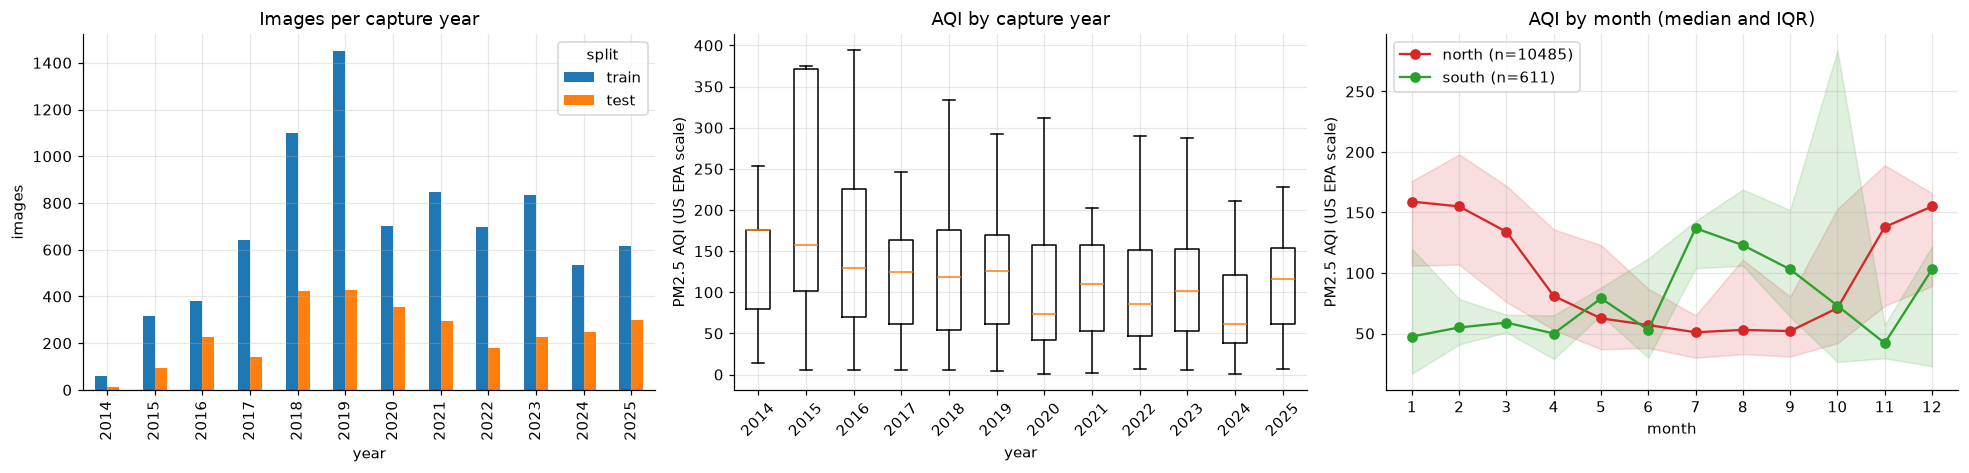

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
images_per_year = clean_metadata.groupby(["year", "split"]).size().unstack("split").reindex(columns=list(SPLITS)).fillna(0)
images_per_year.plot.bar(ax=axes[0], color=[SPLIT_COLORS[split] for split in SPLITS])
axes[0].set(title="Images per capture year", xlabel="year", ylabel="images")

years = sorted(clean_metadata["year"].unique())
axes[1].boxplot([clean_metadata.loc[clean_metadata["year"] == year, TARGET] for year in years], tick_labels=years, showfliers=False)
axes[1].set(title="AQI by capture year", xlabel="year", ylabel=TARGET_LABEL)
axes[1].tick_params(axis="x", rotation=45)

for hemisphere, color in (("north", "tab:red"), ("south", "tab:green")):
    monthly = clean_metadata[clean_metadata["hemisphere"] == hemisphere].groupby("month")[TARGET]
    axes[2].plot(monthly.median().index, monthly.median(), marker="o", color=color, label=f"{hemisphere} (n={monthly.size().sum()})")
    axes[2].fill_between(monthly.median().index, monthly.quantile(0.25), monthly.quantile(0.75), color=color, alpha=0.15)
axes[2].set(title="AQI by month (median and IQR)", xlabel="month", ylabel=TARGET_LABEL, xticks=range(1, 13))
axes[2].legend()
plt.tight_layout()
plt.show()

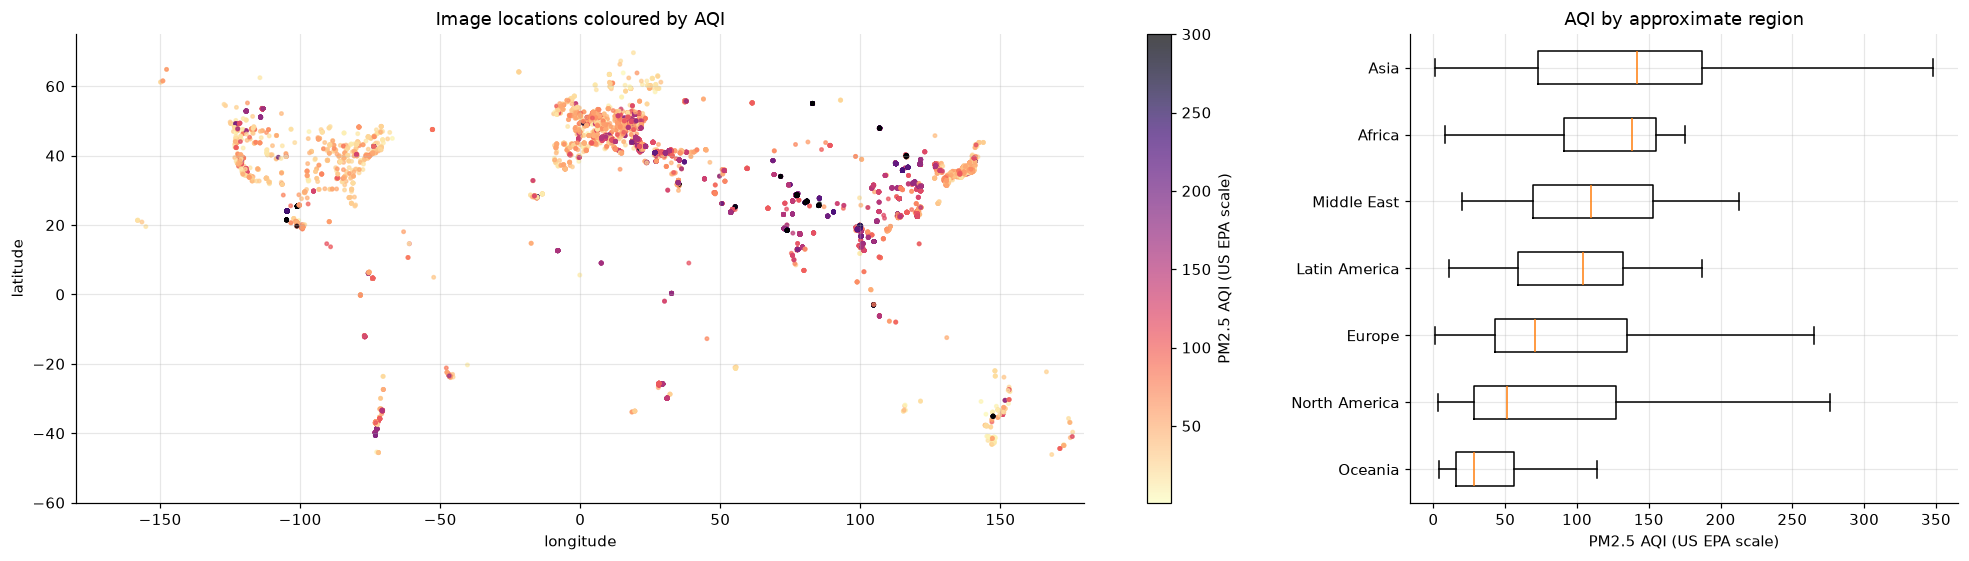

split,train,test,median_aqi
region,,,
Oceania,116,53,28.0
North America,945,281,51.0
Europe,2128,810,71.0
Latin America,283,66,104.0
Middle East,295,143,109.5
Africa,130,119,138.0
Asia,4279,1448,142.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.2), gridspec_kw={"width_ratios": [2.3, 1]})
locations = axes[0].scatter(clean_metadata["longitude"], clean_metadata["latitude"], c=clean_metadata[TARGET], cmap="magma_r", vmax=300, s=5, alpha=0.7)
axes[0].set(xlim=(-180, 180), ylim=(-60, 75), xlabel="longitude", ylabel="latitude", title="Image locations coloured by AQI")
fig.colorbar(locations, ax=axes[0], label=TARGET_LABEL)

region_order = clean_metadata.groupby("region")[TARGET].median().sort_values().index.tolist()
axes[1].boxplot([clean_metadata.loc[clean_metadata["region"] == region, TARGET] for region in region_order], tick_labels=region_order, orientation="horizontal", showfliers=False)
axes[1].set(title="AQI by approximate region", xlabel=TARGET_LABEL)
plt.tight_layout()
plt.show()

region_table = pd.crosstab(clean_metadata["region"], clean_metadata["split"])[list(SPLITS)]
region_table["median_aqi"] = clean_metadata.groupby("region")[TARGET].median()
region_table.sort_values("median_aqi")

stations per split: {'train': 2528, 'test': 729}
stations shared by train and test: 0
images that share station and capture day with another image: 7596

        count  mean   std  min  25%  50%  75%   max
split                                              
test    729.0  4.01  7.93  1.0  1.0  2.0  3.0  76.0
train  2528.0  3.23  6.61  1.0  1.0  2.0  3.0  91.0


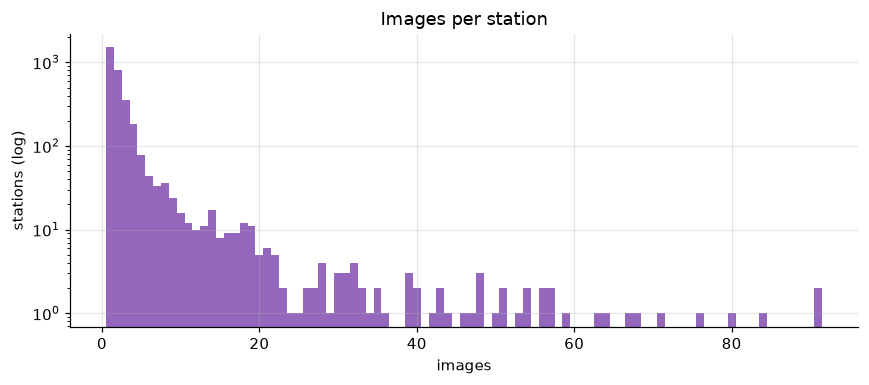

In [12]:
station_summary = clean_metadata.groupby(["split", "station_id"]).agg(
    images=("image_id", "size"),
    capture_days=("captured_at", "nunique"),
    aqi_std=(TARGET, "std"),
)
train_stations = set(clean_metadata.loc[clean_metadata["split"] == "train", "station_id"])
test_stations = set(clean_metadata.loc[clean_metadata["split"] == "test", "station_id"])
images_per_station_day = clean_metadata.groupby(["split", "station_id", "captured_at"]).size()

print("stations per split:", {"train": len(train_stations), "test": len(test_stations)})
print("stations shared by train and test:", len(train_stations & test_stations))
print("images that share station and capture day with another image:", int(images_per_station_day[images_per_station_day > 1].sum()))
print()
print(station_summary.groupby("split")["images"].describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(station_summary["images"], bins=np.arange(1, station_summary["images"].max() + 2) - 0.5, color="tab:purple")
ax.set(yscale="log", title="Images per station", xlabel="images", ylabel="stations (log)")
plt.tight_layout()
plt.show()

colour modes: {'RGB': 11096}
width range: 320 - 1024 | height range: 240 - 1535
most common aspect ratios: {1.33: 5701, 1.78: 4721, 1.35: 100, 1.67: 87, 1.34: 86}


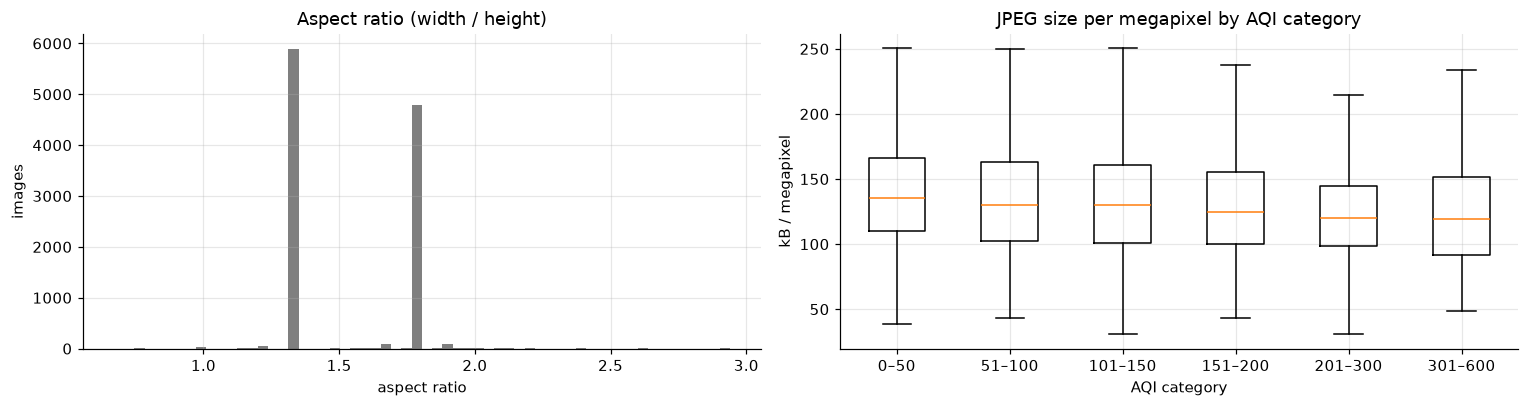

In [13]:
def read_image_properties(image_path):
    with Image.open(image_path) as image:
        width, height = image.size
        return width, height, image.mode, Path(image_path).stat().st_size / 1024


with ThreadPoolExecutor(LOADER_THREADS) as pool:
    image_properties = list(pool.map(read_image_properties, clean_metadata["image_path"]))
clean_metadata[["width", "height", "mode", "file_kb"]] = pd.DataFrame(image_properties, index=clean_metadata.index)
clean_metadata["aspect_ratio"] = (clean_metadata["width"] / clean_metadata["height"]).round(2)
clean_metadata["jpeg_kb_per_megapixel"] = clean_metadata["file_kb"] / (clean_metadata["width"] * clean_metadata["height"] / 1e6)

print("colour modes:", clean_metadata["mode"].value_counts().to_dict())
print("width range:", clean_metadata["width"].min(), "-", clean_metadata["width"].max(), "| height range:", clean_metadata["height"].min(), "-", clean_metadata["height"].max())
print("most common aspect ratios:", clean_metadata["aspect_ratio"].value_counts().head(5).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(clean_metadata["aspect_ratio"], bins=60, color="tab:gray")
axes[0].set(title="Aspect ratio (width / height)", xlabel="aspect ratio", ylabel="images")
axes[1].boxplot([clean_metadata.loc[clean_metadata["pm25_bin"] == aqi_bin, "jpeg_kb_per_megapixel"] for aqi_bin in AQI_BIN_ORDER], tick_labels=AQI_BIN_ORDER, showfliers=False)
axes[1].set(title="JPEG size per megapixel by AQI category", xlabel="AQI category", ylabel="kB / megapixel")
plt.tight_layout()
plt.show()

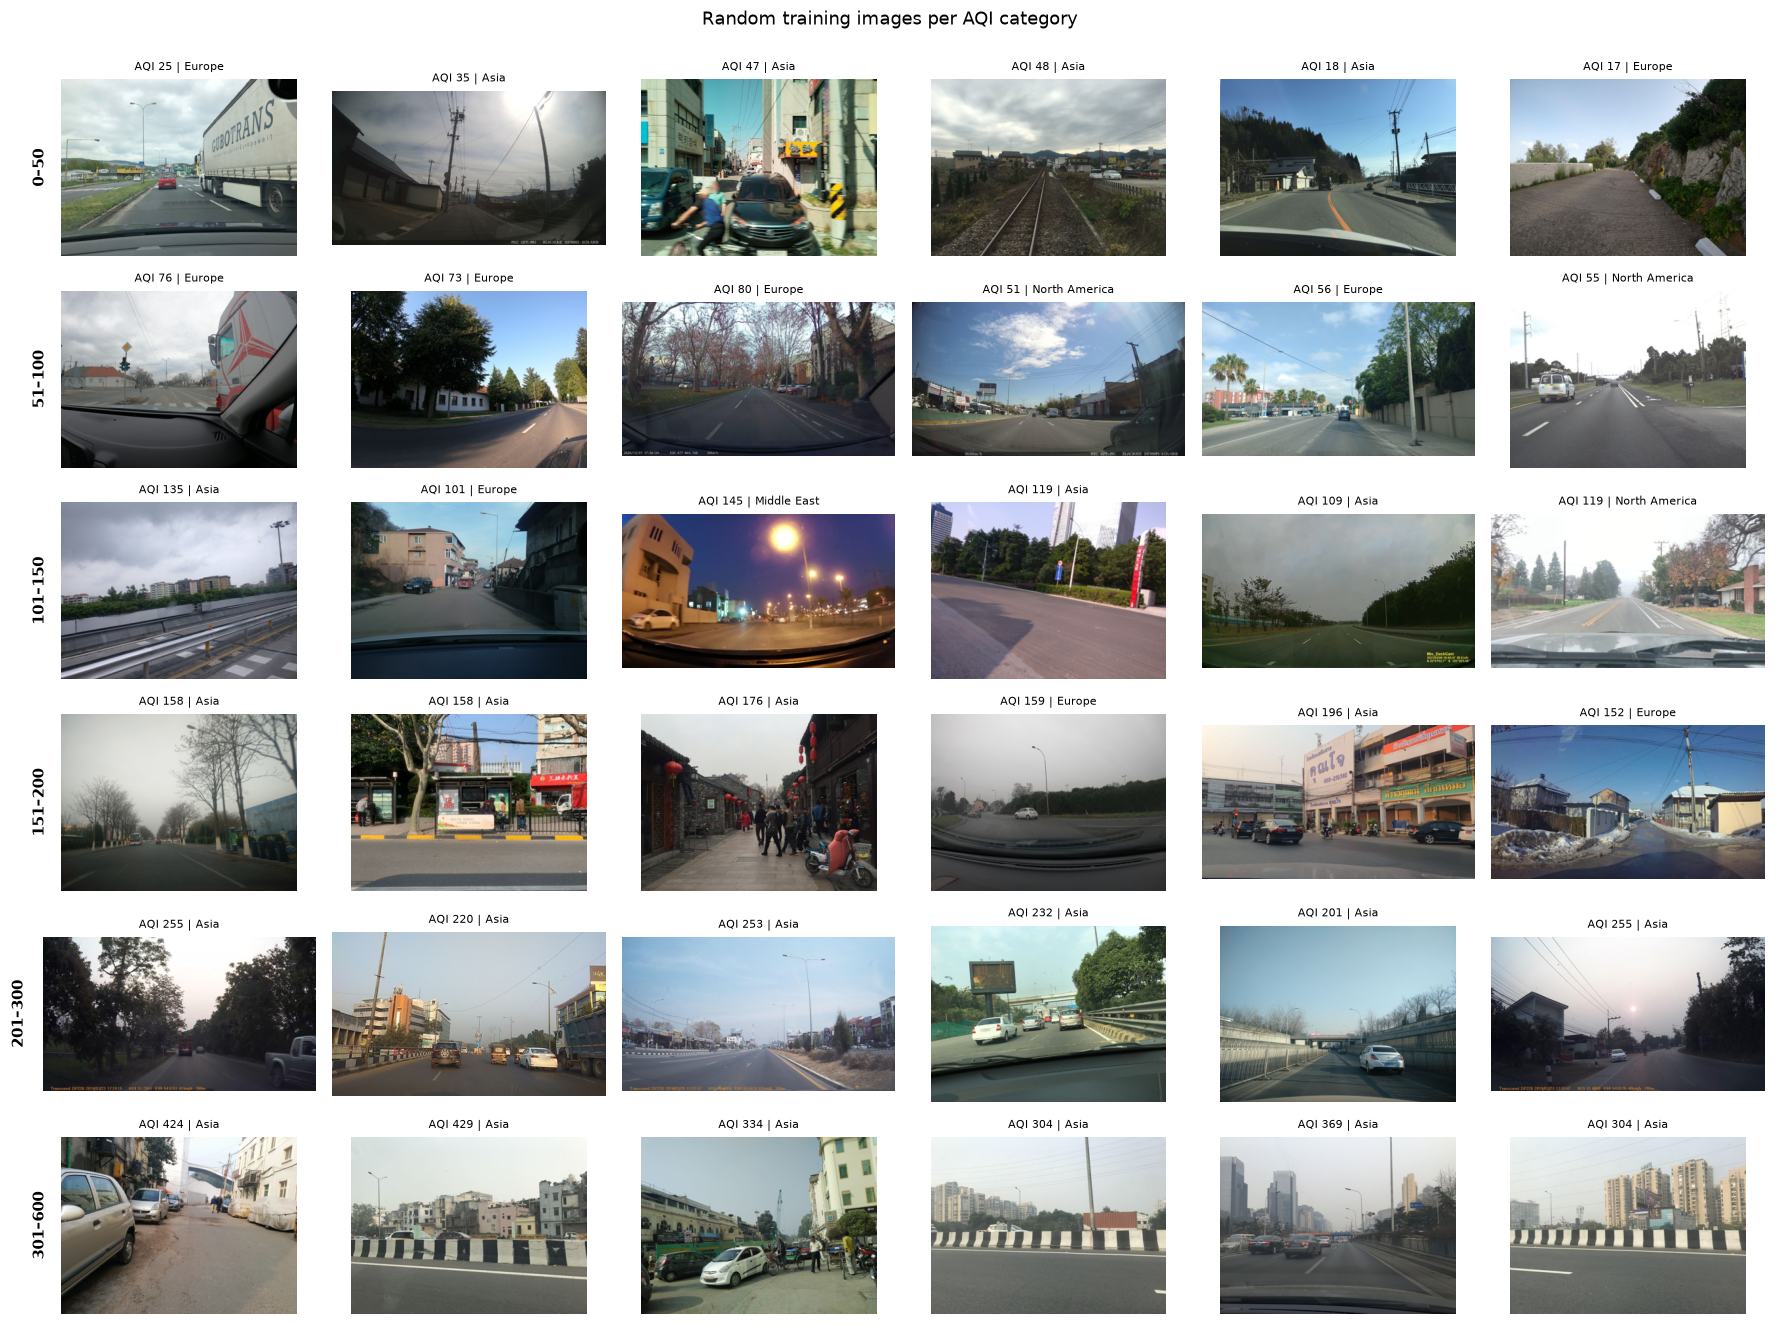

In [14]:
SAMPLES_PER_BIN = 6
train_metadata = clean_metadata[clean_metadata["split"] == "train"]
fig, axes = plt.subplots(len(AQI_BIN_ORDER), SAMPLES_PER_BIN, figsize=(2.7 * SAMPLES_PER_BIN, 2.0 * len(AQI_BIN_ORDER)))
for row_axes, aqi_bin in zip(axes, AQI_BIN_ORDER):
    examples = train_metadata[train_metadata["pm25_bin"] == aqi_bin].sample(SAMPLES_PER_BIN, random_state=RANDOM_SEED)
    for ax, example in zip(row_axes, examples.itertuples()):
        with Image.open(example.image_path) as image:
            image.thumbnail((360, 360))
            ax.imshow(np.asarray(image.convert("RGB")))
        ax.set_title(f"AQI {example.pm25:.0f} | {example.region}", fontsize=7)
        ax.axis("off")
    row_axes[0].text(-0.06, 0.5, aqi_bin, transform=row_axes[0].transAxes, rotation=90, ha="right", va="center", fontsize=10, fontweight="bold")
fig.suptitle("Random training images per AQI category", y=1.0)
plt.tight_layout()
plt.show()

In [15]:
def load_image_tensor(image_path, size):
    height, width = size
    with Image.open(image_path) as image:
        image.draft("RGB", (width, height))
        resized = image.convert("RGB").resize((width, height), Image.Resampling.BILINEAR)
    return torch.from_numpy(np.asarray(resized).copy()).permute(2, 0, 1)


def iterate_image_batches(image_paths, size, batch_size=BATCH_SIZE):
    image_paths = list(image_paths)
    with ThreadPoolExecutor(LOADER_THREADS) as pool:
        for start in range(0, len(image_paths), batch_size):
            batch_paths = image_paths[start:start + batch_size]
            yield torch.stack(list(pool.map(lambda path: load_image_tensor(path, size), batch_paths)))


first_batch = next(iterate_image_batches(clean_metadata["image_path"][:8], FILTER_IMAGE_SIZE))
print("batch tensor:", tuple(first_batch.shape), first_batch.dtype)

batch tensor: (8, 3, 384, 512) torch.uint8


In [16]:
LUMA_WEIGHTS = torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)
LAPLACIAN_KERNEL = torch.tensor([[0.0, 1.0, 0.0], [1.0, -4.0, 1.0], [0.0, 1.0, 0.0]]).view(1, 1, 3, 3)
SOBEL_X_KERNEL = torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]]).view(1, 1, 3, 3)
DARK_CHANNEL_PATCH = 15
LOCAL_CONTRAST_WINDOW = 15
HAZE_OMEGA = 0.95
AIRLIGHT_TOP_FRACTION = 0.001


def luminance(rgb):
    return (rgb * LUMA_WEIGHTS.to(rgb.device)).sum(dim=1, keepdim=True)


def min_filter(single_channel, patch_size):
    return -F.max_pool2d(-single_channel, kernel_size=patch_size, stride=1, padding=patch_size // 2)


def dark_channel(rgb, patch_size=DARK_CHANNEL_PATCH):
    return min_filter(rgb.min(dim=1, keepdim=True).values, patch_size)


def atmospheric_light(rgb, dark):
    flat_dark = dark.flatten(1)
    brightest_haze_pixels = flat_dark.topk(max(1, int(flat_dark.shape[1] * AIRLIGHT_TOP_FRACTION)), dim=1).indices
    airlight = rgb.flatten(2).gather(2, brightest_haze_pixels.unsqueeze(1).expand(-1, 3, -1)).mean(dim=2)
    return airlight.view(rgb.shape[0], 3, 1, 1)


def transmission(rgb, omega=HAZE_OMEGA):
    airlight = atmospheric_light(rgb, dark_channel(rgb))
    return 1 - omega * dark_channel(rgb / airlight.clamp(min=1e-3))


def brightness(rgb):
    return rgb.max(dim=1, keepdim=True).values


def saturation(rgb):
    channel_max = rgb.max(dim=1, keepdim=True).values
    channel_min = rgb.min(dim=1, keepdim=True).values
    return (channel_max - channel_min) / channel_max.clamp(min=1e-6)


def color_attenuation(rgb):
    return brightness(rgb) - saturation(rgb)


def local_contrast(rgb, window=LOCAL_CONTRAST_WINDOW):
    gray = luminance(rgb)
    local_mean = F.avg_pool2d(gray, window, stride=1, padding=window // 2, count_include_pad=False)
    local_mean_of_squares = F.avg_pool2d(gray ** 2, window, stride=1, padding=window // 2, count_include_pad=False)
    return (local_mean_of_squares - local_mean ** 2).clamp(min=0).sqrt()


def laplacian_magnitude(rgb):
    return F.conv2d(luminance(rgb), LAPLACIAN_KERNEL.to(rgb.device), padding=1).abs()


def sobel_magnitude(rgb):
    gray = luminance(rgb)
    kernel_x = SOBEL_X_KERNEL.to(rgb.device)
    gradient_x = F.conv2d(gray, kernel_x, padding=1)
    gradient_y = F.conv2d(gray, kernel_x.transpose(2, 3), padding=1)
    return torch.sqrt(gradient_x ** 2 + gradient_y ** 2)


def blue_ratio(rgb):
    return rgb[:, 2:3] / rgb.sum(dim=1, keepdim=True).clamp(min=1e-6)


FILTER_BANK = {
    "dark_channel": dark_channel,
    "transmission": transmission,
    "brightness": brightness,
    "saturation": saturation,
    "color_attenuation": color_attenuation,
    "local_contrast": local_contrast,
    "laplacian": laplacian_magnitude,
    "sobel": sobel_magnitude,
    "blue_ratio": blue_ratio,
}
print("filters in the bank:", list(FILTER_BANK))

filters in the bank: ['dark_channel', 'transmission', 'brightness', 'saturation', 'color_attenuation', 'local_contrast', 'laplacian', 'sobel', 'blue_ratio']


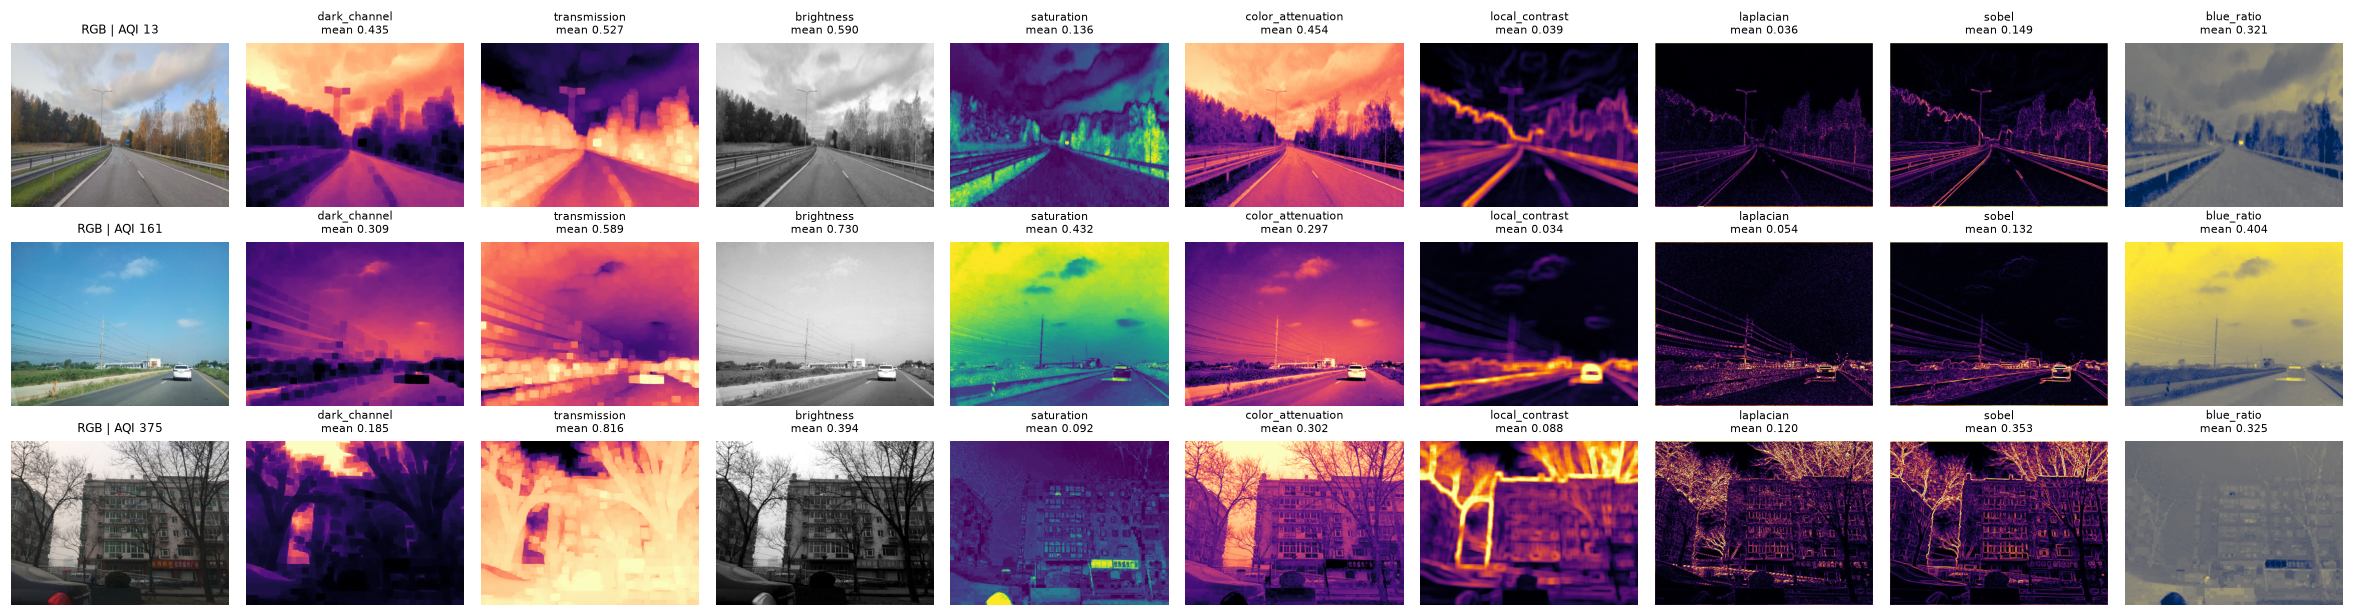

In [17]:
FILTER_COLORMAPS = {"dark_channel": "magma", "transmission": "magma", "brightness": "gray", "saturation": "viridis", "color_attenuation": "magma", "local_contrast": "inferno", "laplacian": "inferno", "sobel": "inferno", "blue_ratio": "cividis"}
example_bins = ["0–50", "151–200", "301–600"]
filter_examples = pd.concat([
    train_metadata[train_metadata["pm25_bin"] == aqi_bin].sample(1, random_state=RANDOM_SEED + 1) for aqi_bin in example_bins
])
example_rgb = torch.stack([load_image_tensor(path, FILTER_IMAGE_SIZE) for path in filter_examples["image_path"]]).to(DEVICE).float() / 255
example_maps = {name: build_map(example_rgb).squeeze(1).cpu().numpy() for name, build_map in FILTER_BANK.items()}

fig, axes = plt.subplots(len(filter_examples), len(FILTER_BANK) + 1, figsize=(2.15 * (len(FILTER_BANK) + 1), 1.9 * len(filter_examples)))
for row, example in enumerate(filter_examples.itertuples()):
    axes[row, 0].imshow(example_rgb[row].permute(1, 2, 0).cpu().numpy())
    axes[row, 0].set_title(f"RGB | AQI {example.pm25:.0f}", fontsize=8)
    for column, (name, maps) in enumerate(example_maps.items(), start=1):
        low, high = np.percentile(maps, [1, 99])
        axes[row, column].imshow(maps[row], cmap=FILTER_COLORMAPS[name], vmin=low, vmax=high)
        axes[row, column].set_title(f"{name}\nmean {maps[row].mean():.3f}", fontsize=7)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [18]:
QUANTILE_LEVELS = (0.1, 0.9)


def image_regions(height):
    sky_end = int(height * SKY_ROI_FRACTION)
    return {"full": slice(0, height), "sky": slice(0, sky_end), "ground": slice(sky_end, height)}


def luminance_entropy(gray):
    levels = (gray.clamp(0, 1) * 255).round().long().flatten(1)
    counts = torch.zeros(levels.shape[0], 256, device=gray.device).scatter_add_(1, levels, torch.ones_like(levels, dtype=torch.float32))
    probabilities = counts / counts.sum(dim=1, keepdim=True)
    return -(probabilities * torch.log2(probabilities.clamp(min=1e-12))).sum(dim=1)


def colorfulness(rgb):
    red, green, blue = rgb[:, 0].flatten(1), rgb[:, 1].flatten(1), rgb[:, 2].flatten(1)
    red_green = red - green
    yellow_blue = 0.5 * (red + green) - blue
    return torch.sqrt(red_green.std(dim=1) ** 2 + yellow_blue.std(dim=1) ** 2) + 0.3 * torch.sqrt(red_green.mean(dim=1) ** 2 + yellow_blue.mean(dim=1) ** 2)


def extract_filter_features(rgb):
    filter_maps = {name: build_map(rgb) for name, build_map in FILTER_BANK.items()}
    gray = luminance(rgb)
    quantile_levels = torch.tensor(QUANTILE_LEVELS, device=rgb.device)
    airlight = atmospheric_light(rgb, filter_maps["dark_channel"]).flatten(1)
    features = {f"global.airlight.{channel}": airlight[:, index] for index, channel in enumerate("rgb")}
    for region, rows in image_regions(rgb.shape[2]).items():
        region_gray = gray[:, :, rows]
        features[f"{region}.rms_contrast.value"] = region_gray.flatten(1).std(dim=1)
        features[f"{region}.entropy.value"] = luminance_entropy(region_gray)
        features[f"{region}.colorfulness.value"] = colorfulness(rgb[:, :, rows])
        for name, feature_map in filter_maps.items():
            values = feature_map[:, :, rows].flatten(1)
            low, high = torch.quantile(values, quantile_levels, dim=1)
            features[f"{region}.{name}.mean"] = values.mean(dim=1)
            features[f"{region}.{name}.p10"] = low
            features[f"{region}.{name}.p90"] = high
    return {name: value.float().cpu().numpy() for name, value in features.items()}


preview_features = extract_filter_features(example_rgb)
print(f"{len(preview_features)} filter features per image, e.g.:", list(preview_features)[:6])

93 filter features per image, e.g.: ['global.airlight.r', 'global.airlight.g', 'global.airlight.b', 'full.rms_contrast.value', 'full.entropy.value', 'full.colorfulness.value']


In [19]:
ID_COLUMNS = ["image_id", "split", "station_id", "region", "captured_at", TARGET, "pm25_bin"]
extraction_start = time.time()
feature_batches = []
total_batches = int(np.ceil(len(clean_metadata) / BATCH_SIZE))
with torch.inference_mode():
    for batch_index, batch in enumerate(iterate_image_batches(clean_metadata["image_path"], FILTER_IMAGE_SIZE), start=1):
        feature_batches.append(pd.DataFrame(extract_filter_features(batch.to(DEVICE).float() / 255)))
        if batch_index % 40 == 0 or batch_index == total_batches:
            print(f"batch {batch_index}/{total_batches} | {time.time() - extraction_start:.0f}s")

filter_features = pd.concat(feature_batches, ignore_index=True)
filter_features["global.jpeg_size.kb_per_megapixel"] = clean_metadata["jpeg_kb_per_megapixel"].to_numpy()
handcrafted_features = pd.concat([clean_metadata[ID_COLUMNS].reset_index(drop=True), filter_features], axis=1)
handcrafted_feature_names = list(filter_features.columns)
print("feature table:", handcrafted_features.shape, "| missing values:", int(handcrafted_features[handcrafted_feature_names].isna().sum().sum()))
handcrafted_features.to_csv(FEATURES_DIR / "handcrafted_filter_features.csv", index=False)
handcrafted_features[ID_COLUMNS + handcrafted_feature_names[:5]].head()

batch 40/174 | 20s
batch 80/174 | 39s
batch 120/174 | 58s
batch 160/174 | 77s
batch 174/174 | 84s
feature table: (11096, 101) | missing values: 0


,image_id,split,station_id,region,captured_at,pm25,pm25_bin,global.airlight.r,global.airlight.g,global.airlight.b,full.rms_contrast.value,full.entropy.value
0,1299925057505266,train,13051,Asia,2024-01-17,39.0,0–50,0.602621,0.686835,0.716787,0.237359,6.860583
1,924249681642820,train,3705,Asia,2017-12-30,19.0,0–50,0.971188,0.981253,0.986214,0.270205,7.338786
2,498043544721455,train,3278,Oceania,2020-01-02,9.0,0–50,0.831773,0.952381,0.998319,0.155179,7.087355
3,944035996420125,train,11580,Africa,2019-06-27,31.0,0–50,0.849780,0.936615,0.989476,0.197762,7.240451
4,886419591948919,train,6894,Europe,2020-04-24,41.0,0–50,0.959324,0.923649,0.893457,0.243586,7.612739


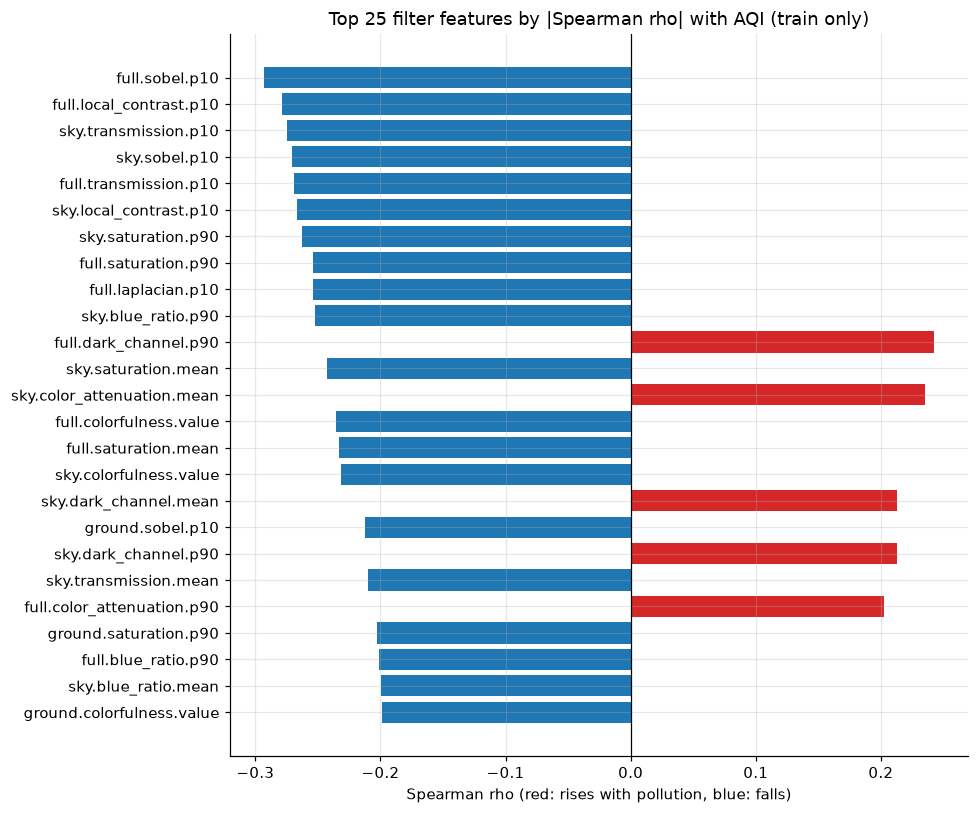

,spearman_rho,region,filter,statistic,abs_rho
full.sobel.p10,-0.293435,full,sobel,p10,0.293435
full.local_contrast.p10,-0.278496,full,local_contrast,p10,0.278496
sky.transmission.p10,-0.275026,sky,transmission,p10,0.275026
sky.sobel.p10,-0.270335,sky,sobel,p10,0.270335
full.transmission.p10,-0.269097,full,transmission,p10,0.269097
sky.local_contrast.p10,-0.266545,sky,local_contrast,p10,0.266545
sky.saturation.p90,-0.262870,sky,saturation,p90,0.262870
full.saturation.p90,-0.253989,full,saturation,p90,0.253989
full.laplacian.p10,-0.253512,full,laplacian,p10,0.253512
sky.blue_ratio.p90,-0.252135,sky,blue_ratio,p90,0.252135


In [20]:
def spearman_with_target(feature_table, target):
    return feature_table.rank().corrwith(target.rank())


def describe_feature(feature_name):
    region, filter_name, statistic = feature_name.split(".")
    return region, filter_name, statistic


train_features = handcrafted_features[handcrafted_features["split"] == "train"].reset_index(drop=True)
test_features = handcrafted_features[handcrafted_features["split"] == "test"].reset_index(drop=True)

filter_ranking = spearman_with_target(train_features[handcrafted_feature_names], train_features[TARGET]).rename("spearman_rho").to_frame()
filter_ranking[["region", "filter", "statistic"]] = [describe_feature(name) for name in filter_ranking.index]
filter_ranking["abs_rho"] = filter_ranking["spearman_rho"].abs()
filter_ranking = filter_ranking.sort_values("abs_rho", ascending=False)

top_ranked = filter_ranking.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(top_ranked.index, top_ranked["spearman_rho"], color=np.where(top_ranked["spearman_rho"] > 0, "tab:red", "tab:blue"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Top 25 filter features by |Spearman rho| with AQI (train only)", xlabel="Spearman rho (red: rises with pollution, blue: falls)")
plt.tight_layout()
plt.show()
filter_ranking.head(15)

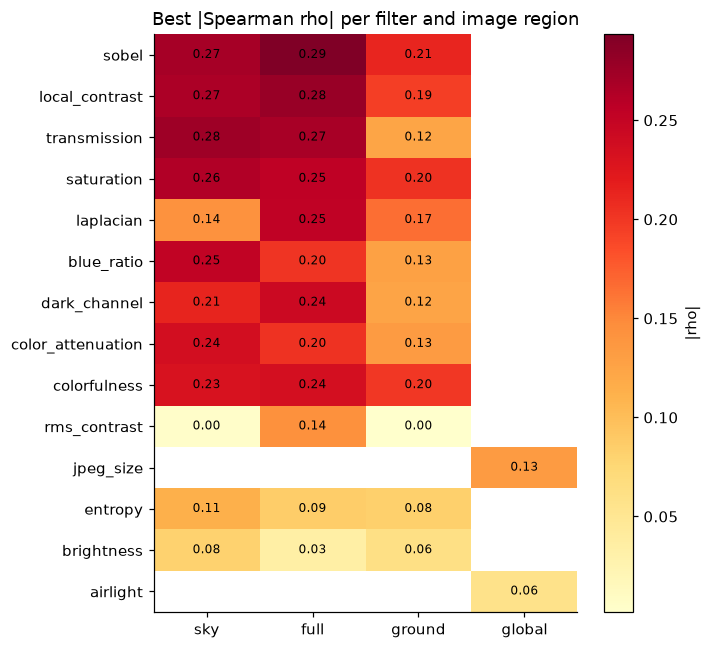

region,sky,full,ground,global
filter,,,,
sobel,0.270,0.293,0.213,NaN
local_contrast,0.267,0.278,0.195,NaN
transmission,0.275,0.269,0.123,NaN
saturation,0.263,0.254,0.202,NaN
laplacian,0.142,0.254,0.165,NaN
blue_ratio,0.252,0.201,0.128,NaN
dark_channel,0.213,0.243,0.124,NaN
color_attenuation,0.235,0.203,0.133,NaN
colorfulness,0.231,0.235,0.199,NaN


In [21]:
best_rho_per_filter_and_region = filter_ranking.pivot_table(index="filter", columns="region", values="abs_rho", aggfunc="max")
best_rho_per_filter_and_region = best_rho_per_filter_and_region.reindex(columns=["sky", "full", "ground", "global"]).dropna(axis=1, how="all")
best_rho_per_filter_and_region = best_rho_per_filter_and_region.loc[best_rho_per_filter_and_region.max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(6.5, 6))
heatmap = ax.imshow(best_rho_per_filter_and_region.to_numpy(dtype=float), cmap="YlOrRd", aspect="auto")
ax.set(xticks=range(best_rho_per_filter_and_region.shape[1]), xticklabels=best_rho_per_filter_and_region.columns,
       yticks=range(best_rho_per_filter_and_region.shape[0]), yticklabels=best_rho_per_filter_and_region.index,
       title="Best |Spearman rho| per filter and image region")
for (row, column), value in np.ndenumerate(best_rho_per_filter_and_region.to_numpy(dtype=float)):
    if not np.isnan(value):
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(heatmap, ax=ax, label="|rho|")
plt.tight_layout()
plt.show()
best_rho_per_filter_and_region.round(3)

regions used: {'Asia': 4279, 'Europe': 2128, 'North America': 945, 'Middle East': 295, 'Latin America': 283}


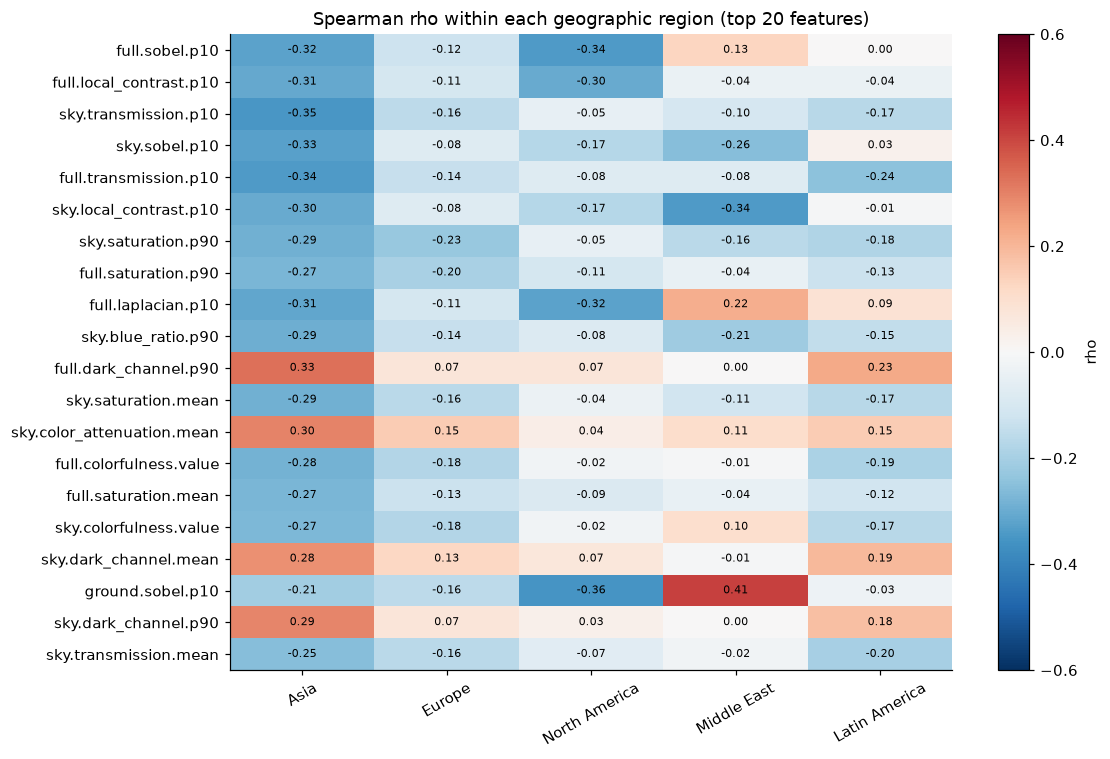

In [22]:
MIN_IMAGES_PER_REGION = 150
regions_with_enough_images = train_features["region"].value_counts().loc[lambda counts: counts >= MIN_IMAGES_PER_REGION].index.tolist()
rho_by_geographic_region = pd.DataFrame({
    region: spearman_with_target(
        train_features.loc[train_features["region"] == region, handcrafted_feature_names],
        train_features.loc[train_features["region"] == region, TARGET],
    )
    for region in regions_with_enough_images
})
filter_ranking["sign_consistency"] = np.sign(rho_by_geographic_region).eq(np.sign(filter_ranking["spearman_rho"]), axis=0).mean(axis=1)

top_features_by_region = rho_by_geographic_region.loc[filter_ranking.index[:20]]
fig, ax = plt.subplots(figsize=(1.1 * len(regions_with_enough_images) + 5, 7))
heatmap = ax.imshow(top_features_by_region.to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set(xticks=range(len(regions_with_enough_images)), xticklabels=regions_with_enough_images,
       yticks=range(len(top_features_by_region)), yticklabels=top_features_by_region.index,
       title="Spearman rho within each geographic region (top 20 features)")
ax.tick_params(axis="x", rotation=30)
for (row, column), value in np.ndenumerate(top_features_by_region.to_numpy()):
    ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(heatmap, ax=ax, label="rho")
plt.tight_layout()
plt.show()
print("regions used:", train_features["region"].value_counts().loc[regions_with_enough_images].to_dict())

selected 12 non-redundant filters (|rank corr| < 0.85, same sign in >= 80% of regions)


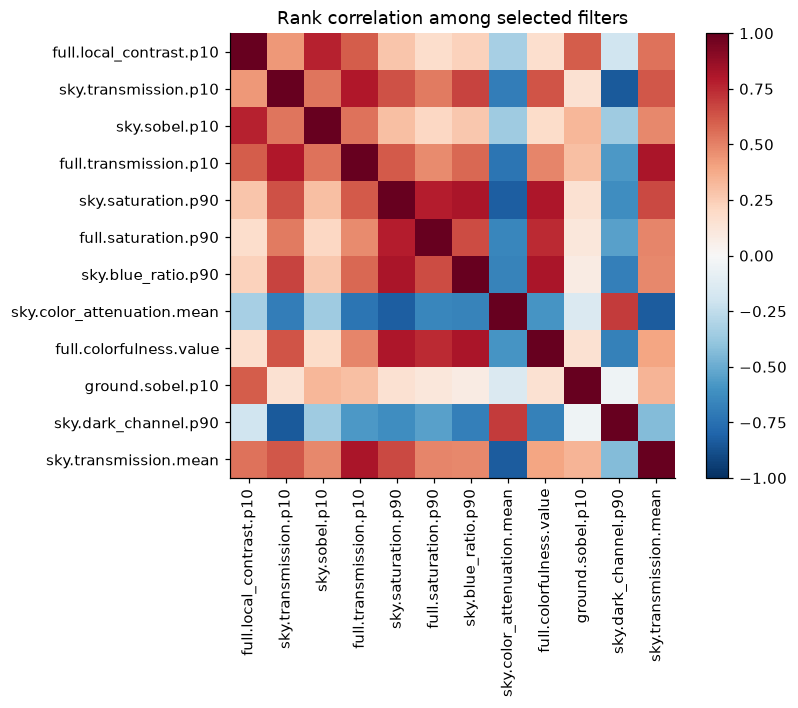

,region,filter,statistic,spearman_rho,sign_consistency
full.local_contrast.p10,full,local_contrast,p10,-0.278,1.0
sky.transmission.p10,sky,transmission,p10,-0.275,1.0
sky.sobel.p10,sky,sobel,p10,-0.270,0.8
full.transmission.p10,full,transmission,p10,-0.269,1.0
sky.saturation.p90,sky,saturation,p90,-0.263,1.0
full.saturation.p90,full,saturation,p90,-0.254,1.0
sky.blue_ratio.p90,sky,blue_ratio,p90,-0.252,1.0
sky.color_attenuation.mean,sky,color_attenuation,mean,0.235,1.0
full.colorfulness.value,full,colorfulness,value,-0.235,1.0
ground.sobel.p10,ground,sobel,p10,-0.213,0.8


In [23]:
MAX_SELECTED_FILTERS = 12
REDUNDANCY_THRESHOLD = 0.85
MIN_SIGN_CONSISTENCY = 0.8

feature_rank_correlation = train_features[handcrafted_feature_names].rank().corr()
selected_filters = []
for feature_name in filter_ranking.index[filter_ranking["sign_consistency"] >= MIN_SIGN_CONSISTENCY]:
    if all(abs(feature_rank_correlation.loc[feature_name, kept]) < REDUNDANCY_THRESHOLD for kept in selected_filters):
        selected_filters.append(feature_name)
    if len(selected_filters) == MAX_SELECTED_FILTERS:
        break

selected_filter_table = filter_ranking.loc[selected_filters, ["region", "filter", "statistic", "spearman_rho", "sign_consistency"]]
print(f"selected {len(selected_filters)} non-redundant filters (|rank corr| < {REDUNDANCY_THRESHOLD}, same sign in >= {MIN_SIGN_CONSISTENCY:.0%} of regions)")

fig, ax = plt.subplots(figsize=(8, 6.5))
heatmap = ax.imshow(feature_rank_correlation.loc[selected_filters, selected_filters].to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(len(selected_filters)), xticklabels=selected_filters, yticks=range(len(selected_filters)), yticklabels=selected_filters, title="Rank correlation among selected filters")
ax.tick_params(axis="x", rotation=90)
ax.grid(False)
fig.colorbar(heatmap, ax=ax)
plt.tight_layout()
plt.show()
selected_filter_table.round(3)

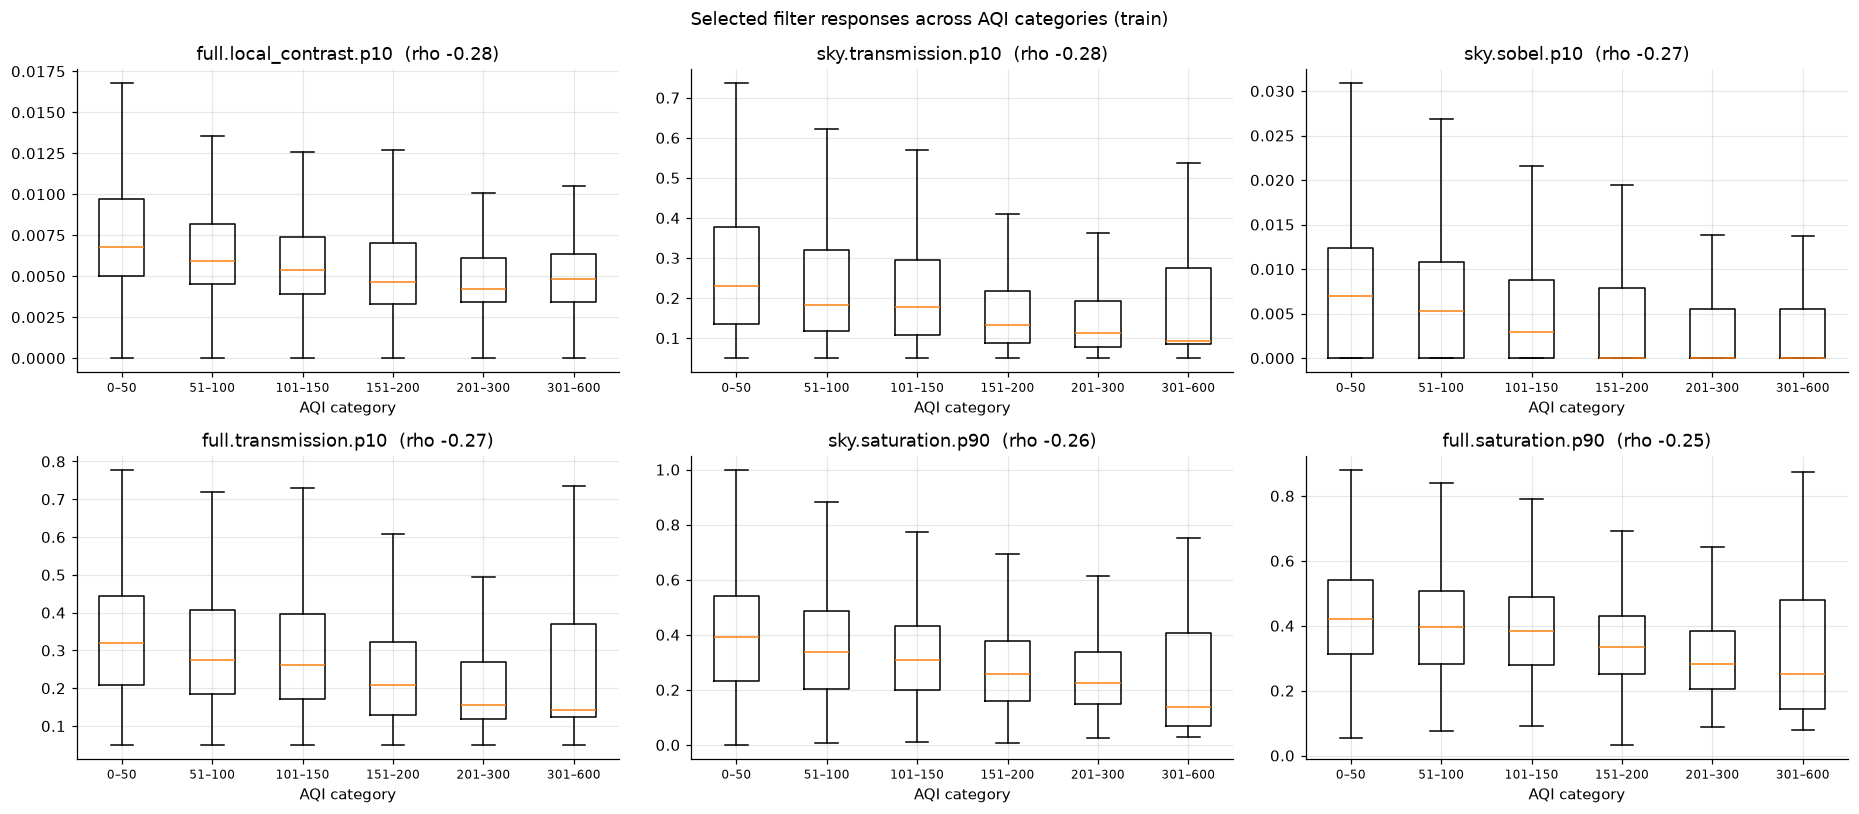

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7.5))
for ax, feature_name in zip(axes.ravel(), selected_filters[:6]):
    ax.boxplot([train_features.loc[train_features["pm25_bin"] == aqi_bin, feature_name] for aqi_bin in AQI_BIN_ORDER], tick_labels=AQI_BIN_ORDER, showfliers=False)
    ax.set(title=f"{feature_name}  (rho {filter_ranking.loc[feature_name, 'spearman_rho']:+.2f})", xlabel="AQI category")
    ax.tick_params(axis="x", labelsize=8)
plt.suptitle("Selected filter responses across AQI categories (train)")
plt.tight_layout()
plt.show()

In [25]:
RIDGE_ALPHAS = (0.1, 1.0, 10.0, 100.0, 1000.0, 3000.0, 10000.0, 30000.0, 100000.0, 300000.0)
CV_FOLDS = 5
MIN_DISTINCT_PREDICTIONS_FOR_RANKING = 10


def station_folds(station_ids, n_folds=CV_FOLDS, seed=RANDOM_SEED):
    stations = np.random.default_rng(seed).permutation(np.unique(station_ids))
    fold_by_station = dict(zip(stations, np.arange(len(stations)) % n_folds))
    return np.array([fold_by_station[station] for station in station_ids])


def fit_ridge(features, target, alpha):
    mean, scale = features.mean(axis=0), features.std(axis=0) + 1e-8
    design = np.c_[np.ones(len(features)), (features - mean) / scale]
    penalty = alpha * np.eye(design.shape[1])
    penalty[0, 0] = 0.0
    coefficients = np.linalg.solve(design.T @ design + penalty, design.T @ target)
    return lambda new_features: np.c_[np.ones(len(new_features)), (new_features - mean) / scale] @ coefficients


def regression_report(true_aqi, predicted_aqi):
    residual = true_aqi - predicted_aqi
    predictions_can_be_ranked = len(np.unique(predicted_aqi)) >= MIN_DISTINCT_PREDICTIONS_FOR_RANKING
    return {
        "MAE": np.abs(residual).mean(),
        "RMSE": np.sqrt((residual ** 2).mean()),
        "R2": 1 - (residual ** 2).sum() / ((true_aqi - true_aqi.mean()) ** 2).sum(),
        "Spearman": pd.Series(true_aqi).rank().corr(pd.Series(predicted_aqi).rank()) if predictions_can_be_ranked else np.nan,
    }


def evaluate_feature_set(train_matrix, test_matrix, alphas=RIDGE_ALPHAS):
    train_aqi, test_aqi = train_features[TARGET].to_numpy(), test_features[TARGET].to_numpy()
    log_train_aqi = np.log1p(train_aqi)
    folds = station_folds(train_features["station_id"].to_numpy())
    best = None
    for alpha in alphas:
        out_of_fold = np.zeros(len(train_aqi))
        for fold in range(CV_FOLDS):
            held_out = folds == fold
            out_of_fold[held_out] = fit_ridge(train_matrix[~held_out], log_train_aqi[~held_out], alpha)(train_matrix[held_out])
        cv_report = regression_report(train_aqi, np.expm1(out_of_fold))
        if best is None or cv_report["MAE"] < best["cv"]["MAE"]:
            best = {"alpha": alpha, "cv": cv_report}
    test_prediction = np.expm1(fit_ridge(train_matrix, log_train_aqi, best["alpha"])(test_matrix))
    best["test"] = regression_report(test_aqi, test_prediction)
    return best


def results_row(name, result):
    return {"feature_set": name, "alpha": result.get("alpha"), **{f"cv_{k}": v for k, v in result["cv"].items()}, **{f"test_{k}": v for k, v in result["test"].items()}}


folds = station_folds(train_features["station_id"].to_numpy())
median_out_of_fold = np.zeros(len(train_features))
for fold in range(CV_FOLDS):
    median_out_of_fold[folds == fold] = train_features.loc[folds != fold, TARGET].median()
median_baseline = {
    "cv": regression_report(train_features[TARGET].to_numpy(), median_out_of_fold),
    "test": regression_report(test_features[TARGET].to_numpy(), np.full(len(test_features), train_features[TARGET].median())),
}

feature_set_results = [
    results_row("train median (no image)", median_baseline),
    results_row(f"all hand-crafted filters ({len(handcrafted_feature_names)})", evaluate_feature_set(train_features[handcrafted_feature_names].to_numpy(), test_features[handcrafted_feature_names].to_numpy())),
    results_row(f"selected filters ({len(selected_filters)})", evaluate_feature_set(train_features[selected_filters].to_numpy(), test_features[selected_filters].to_numpy())),
]
pd.DataFrame(feature_set_results).round(3)

,feature_set,alpha,cv_MAE,cv_RMSE,cv_R2,cv_Spearman,test_MAE,test_RMSE,test_R2,test_Spearman
0,train median (no image),NaN,66.324,89.258,-0.021,NaN,63.636,81.880,-0.011,NaN
1,all hand-crafted filters (94),10.0,58.085,85.119,0.072,0.461,53.181,73.827,0.178,0.525
2,selected filters (12),0.1,62.406,88.888,-0.012,0.354,58.348,79.689,0.043,0.410


In [26]:
efficientnet_weights = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1
embedding_backbone = torchvision.models.efficientnet_b0(weights=efficientnet_weights)
embedding_backbone.classifier = torch.nn.Identity()
embedding_backbone = embedding_backbone.eval().to(DEVICE)
imagenet_mean = torch.tensor(efficientnet_weights.transforms().mean, device=DEVICE).view(1, 3, 1, 1)
imagenet_std = torch.tensor(efficientnet_weights.transforms().std, device=DEVICE).view(1, 3, 1, 1)

embedding_start = time.time()
embedding_batches = []
with torch.inference_mode():
    for batch in iterate_image_batches(clean_metadata["image_path"], DEEP_IMAGE_SIZE):
        rgb = batch.to(DEVICE).float() / 255
        embedding_batches.append(embedding_backbone((rgb - imagenet_mean) / imagenet_std).float().cpu())
deep_embeddings = torch.cat(embedding_batches).numpy()
print(f"EfficientNet-B0 embeddings: {deep_embeddings.shape} in {time.time() - embedding_start:.0f}s")

np.savez_compressed(
    FEATURES_DIR / "efficientnet_b0_embeddings.npz",
    image_id=clean_metadata["image_id"].to_numpy(),
    split=clean_metadata["split"].to_numpy().astype(str),
    embeddings=deep_embeddings.astype(np.float16),
)

EfficientNet-B0 embeddings: (11096, 1280) in 41s


Spearman rho of the first 10 embedding PCs with AQI:
{'PC1': 0.218, 'PC2': 0.058, 'PC3': 0.091, 'PC4': -0.052, 'PC5': 0.062, 'PC6': 0.201, 'PC7': -0.135, 'PC8': -0.001, 'PC9': -0.01, 'PC10': 0.029}


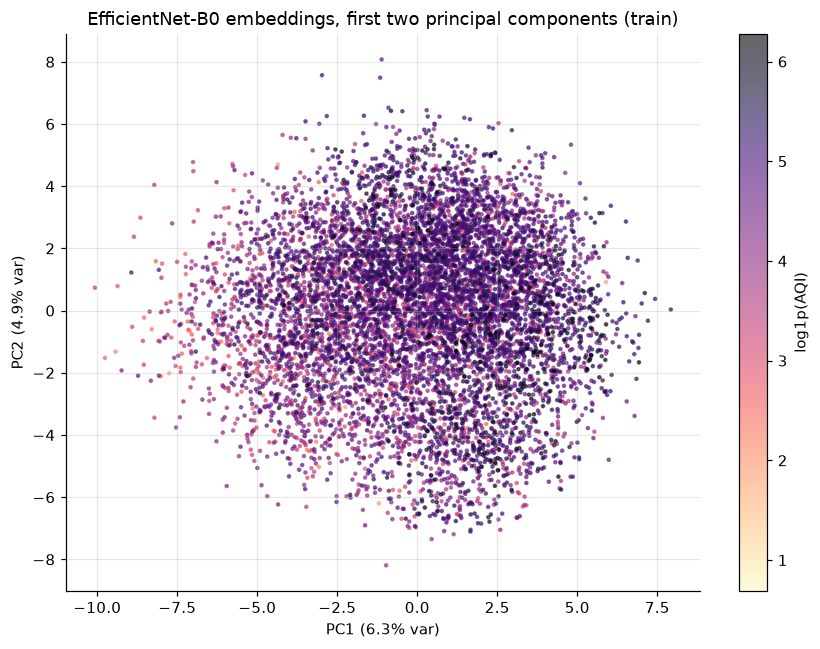

In [30]:
is_train = (clean_metadata["split"] == "train").to_numpy()
train_embeddings, test_embeddings = deep_embeddings[is_train], deep_embeddings[~is_train]

centered_train_embeddings = torch.from_numpy(train_embeddings - train_embeddings.mean(axis=0))
torch.manual_seed(RANDOM_SEED)
_, singular_values, principal_axes = torch.pca_lowrank(centered_train_embeddings, q=10, center=False)
explained_variance_share = (singular_values ** 2 / (centered_train_embeddings ** 2).sum()).numpy()
principal_components = pd.DataFrame((centered_train_embeddings @ principal_axes).numpy(), columns=[f"PC{index + 1}" for index in range(principal_axes.shape[1])])

fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(principal_components["PC1"], principal_components["PC2"], c=np.log1p(train_features[TARGET]), cmap="magma_r", s=4, alpha=0.6)
ax.set(title="EfficientNet-B0 embeddings, first two principal components (train)", xlabel=f"PC1 ({explained_variance_share[0]:.1%} var)", ylabel=f"PC2 ({explained_variance_share[1]:.1%} var)")
fig.colorbar(points, ax=ax, label="log1p(AQI)")
plt.tight_layout()
plt.show()

print("Spearman rho of the first 10 embedding PCs with AQI:")
print(spearman_with_target(principal_components, train_features[TARGET]).round(3).to_dict())

In [28]:
train_selected, test_selected = train_features[selected_filters].to_numpy(), test_features[selected_filters].to_numpy()
feature_set_results += [
    results_row(f"EfficientNet-B0 embeddings ({deep_embeddings.shape[1]})", evaluate_feature_set(train_embeddings, test_embeddings)),
    results_row(f"EfficientNet-B0 + selected filters ({deep_embeddings.shape[1] + len(selected_filters)})", evaluate_feature_set(np.c_[train_embeddings, train_selected], np.c_[test_embeddings, test_selected])),
]
comparison = pd.DataFrame(feature_set_results).drop_duplicates("feature_set", keep="last").set_index("feature_set")
print("Ridge on log1p(AQI); cv = 5-fold station-grouped CV on train, test = unseen stations. MAE/RMSE in AQI units.")
comparison.round(3)

Ridge on log1p(AQI); cv = 5-fold station-grouped CV on train, test = unseen stations. MAE/RMSE in AQI units.


,alpha,cv_MAE,cv_RMSE,cv_R2,cv_Spearman,test_MAE,test_RMSE,test_R2,test_Spearman
feature_set,,,,,,,,,
train median (no image),NaN,66.324,89.258,-0.021,NaN,63.636,81.880,-0.011,NaN
all hand-crafted filters (94),10.0,58.085,85.119,0.072,0.461,53.181,73.827,0.178,0.525
selected filters (12),0.1,62.406,88.888,-0.012,0.354,58.348,79.689,0.043,0.410
EfficientNet-B0 embeddings (1280),3000.0,51.437,77.697,0.227,0.620,49.019,68.122,0.301,0.630
EfficientNet-B0 + selected filters (1292),3000.0,50.915,77.079,0.239,0.626,48.617,67.658,0.310,0.641


In [29]:
selected_filter_report = [
    {
        "feature": name,
        "region": row["region"],
        "filter": row["filter"],
        "statistic": row["statistic"],
        "spearman_rho_train": round(float(row["spearman_rho"]), 4),
        "sign_consistency_across_regions": round(float(row["sign_consistency"]), 3),
    }
    for name, row in selected_filter_table.iterrows()
]
(FEATURES_DIR / "selected_filters.json").write_text(json.dumps(selected_filter_report, indent=2))
clean_metadata.drop(columns=["mode"]).to_csv(FEATURES_DIR / "clean_metadata.csv", index=False)
comparison.round(4).to_csv(FEATURES_DIR / "feature_set_comparison.csv")

for path in sorted(FEATURES_DIR.iterdir()):
    print(f"{path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size / 1e6:.1f} MB)")

features/clean_metadata.csv  (3.3 MB)
features/efficientnet_b0_embeddings.npz  (26.2 MB)
features/feature_set_comparison.csv  (0.0 MB)
features/handcrafted_filter_features.csv  (12.0 MB)
features/selected_filters.json  (0.0 MB)
